# Creating the CREDIT layer — DRC

CREDIT: Custom Residential Demand Indicative Target

--------------------------------------------------------------------------

**Original code:** [Alexandros Korkovelos](https://github.com/akorkovelos) <br />
**Conceptualization & Methodological review :**  [Alexandros Korkovelos](https://github.com/akorkovelos) <br />
**Updates, Modifications:** [Alexandros Korkovelos](https://github.com/akorkovelos) <br />
**Adapted for DRC:** Bachirou <br />
**Funding:** The World Bank

--------------------------------------------------------------------------
Predicting electricity demand in currently un-electrified settlement is a challenge. Many energy access efforts use the multi-tier framework (MTF) as a point of reference; OnSSET in particular, uses this approach as it provides a good basis of (investment) comparison between different levels of access. Access tiers are assigned to settlements based on selection criteria; the most common approach (also adopted in GEP) is to assign tier-targets to urban/rural settlements respectively. This approach allows for limited spatial allocation of targets let alone it does not take into account newly available spatial information.

The **Custom Residential Electricity Demand Indicative Target** (CREDIT) has been developed so as to provide a spatially explicit, alternative approach of predicting electricity demand targets in currently un-electrified settlements, by using poverty and GDP maps. The process is described step-by-step below for the example case of the **Democratic Republic of the Congo (DRC)**. This notebook has been developed to support replication of the process at any stage.

## Preparing the environment

Before starting with the code it is important that the following modules are imported. 

In [1]:
# ============================================
# CORRECTED IMPORTS FOR CREDIT LAYER SCRIPT
# ============================================

# Built-in modules
import os
import sys
import pprint
from pathlib import Path
import logging
import scipy.interpolate

# GDAL/OGR - MUST be imported from osgeo
from osgeo import ogr, gdal, osr

# Spatial analysis libraries
import pysal as ps
import affine
import fiona
import earthpy.plot as ep
from shapely.geometry import box
from shapely.geometry import Point

# Raster processing
import rasterio
import rasterio.mask
from rasterio.enums import Resampling
from rasterio.windows import Window
from rasterio.transform import Affine
from rasterstats import point_query
from rasterio import features
import affine
from rasterio.warp import calculate_default_transform, reproject, Resampling

# Data manipulation
import numpy as np
import pandas as pd
import geopandas as gpd
import csv

# Visualization
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.colors as colors

# Jupyter notebook magic (only for notebooks)
%matplotlib inline

# Print confirmation
print(f"✅ GDAL version: {gdal.__version__}")
print("✅ All imports loaded successfully!")
print(f"✅ Active environment: {sys.prefix}")

C:\Users\Bachirou\miniconda3\envs\credit_env\Lib\site-packages\earthpy\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_string


✅ GDAL version: 3.8.4
✅ All imports loaded successfully!
✅ Active environment: C:\Users\Bachirou\miniconda3\envs\credit_env


## Step 1. Collection of raw GIS data

First, we collect available data for the area/country of interest. In this case we will use the national [GDP, PPP (purchasing-power-parity) values for 2015 in constant 2011 U.S. dollars (USD)](https://gep-onsset.readthedocs.io/en/latest/GIS%20data%20collection.html#gdp-ppp). Poverty maps can be acquired from the [WorldPop](https://www.worldpop.org/geodata/listing?id=23) database in raster format. However, their availability is limited to only a few countries. Therefore here, we describe how can one use tabular data available on administrative level. Values used, indicate the share of population living below the poverty line (defined as $2/day). 

### 1.1 Importing poverty data

You may receive the poverty data in different ways; you may refer to:

- **1.1.a** in case you receive data in csv format
- **1.1.b** in case you receive data in shp
- **1.1.c** in case poverty data is already in .tiff format

#### 1.1.a Poverty data available in tabular (csv) format

**Import csv containing poverty rate/values**

In [2]:
ROOT_DIR = os.path.abspath(os.curdir)
ROOT_DIR

'C:\\Users\\Bachirou\\Documents\\CREDIT_Model_DRC\\Credit_DRC'

In [3]:
import sys, os
sys.path.insert(0, ROOT_DIR)
from extract_poverty import extract_country_tabular

# Download poverty CSV from HDX (skips if already present)
poverty_root = os.path.join(ROOT_DIR, "poverty_data")
poverty_df = extract_country_tabular("Congo, Democratic Republic of the", out_dir=poverty_root)

# Paths for downstream cells
csv_path = os.path.join(poverty_root, "tabular")

# Pick the OPHI MPI CSV (the one with 'MPI' in its name)
_csv_files = [f for f in os.listdir(csv_path) if f.lower().endswith(".csv") and "mpi" in f.lower()]
if not _csv_files:
    _csv_files = [f for f in os.listdir(csv_path) if f.lower().endswith(".csv")]
name_of_csv_file = _csv_files[0]
print(f"CSV ready: {name_of_csv_file}")

[WARNING] Resource 'Democratic Republic of the Congo MPI and Partial Indices' does not appear to mention 'Congo, Democratic Republic of the' — double-check this is the correct country's data before using it.
[SKIP] Congo,_Democratic_Republic_of_the_Democratic_Republic_of_the_Congo_MPI_and_Partial_Indices.csv already exists, not re-downloading.
CSV ready: Congo,_Democratic_Republic_of_the_Democratic_Republic_of_the_Congo_MPI_and_Partial_Indices.csv


In [4]:
# Import csv as pandas dataframe
poverty_data = pd.read_csv(csv_path + "\\" + name_of_csv_file)

In [5]:
poverty_data.head(3)       # in this case the column 'WBG_P2_pov_hcr' provides the headcount poverty rate in a specified year

,Country ISO3,Admin 1 PCode,Admin 1 Name,MPI,Headcount Ratio,Intensity of Deprivation,Vulnerable to Poverty,In Severe Poverty,Survey,Start Date,End Date
0,COD,NaN,NaN,0.3312,64.5180,51.3328,17.4219,36.7755,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00
1,COD,CD10,Kinshasa,0.0684,16.2028,42.1970,17.8629,3.2801,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00
2,COD,CD20,Kongo Central,0.2760,54.2069,50.9221,22.3076,30.7585,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00


In [6]:
# Remove the first row and reset the index so it starts clean at 0
poverty_data= poverty_data.iloc[1:].reset_index(drop=True)
poverty_data.head(3)    

,Country ISO3,Admin 1 PCode,Admin 1 Name,MPI,Headcount Ratio,Intensity of Deprivation,Vulnerable to Poverty,In Severe Poverty,Survey,Start Date,End Date
0,COD,CD10,Kinshasa,0.0684,16.2028,42.1970,17.8629,3.2801,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00
1,COD,CD20,Kongo Central,0.2760,54.2069,50.9221,22.3076,30.7585,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00
2,COD,CD31,Kwango,0.4809,90.1723,53.3347,9.3322,64.2761,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00


In [7]:
# Define output path and filename
output_csv_path = ROOT_DIR + "\\" + 'poverty_data\\tabular' + "\\" + "cod_poverty_data.csv"

# Write to the tabular folder if it doesn't already exist
if not os.path.exists(output_csv_path):
    poverty_data.to_csv(output_csv_path, index=False)
    print(f"[OK] Saved cleaned poverty data to {output_csv_path}")
else:
    print(f"[SKIP] {output_csv_path} already exists, not overwriting.")

poverty_data.head(3)

[SKIP] C:\Users\Bachirou\Documents\CREDIT_Model_DRC\Credit_DRC\poverty_data\tabular\cod_poverty_data.csv already exists, not overwriting.


,Country ISO3,Admin 1 PCode,Admin 1 Name,MPI,Headcount Ratio,Intensity of Deprivation,Vulnerable to Poverty,In Severe Poverty,Survey,Start Date,End Date
0,COD,CD10,Kinshasa,0.0684,16.2028,42.1970,17.8629,3.2801,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00
1,COD,CD20,Kongo Central,0.2760,54.2069,50.9221,22.3076,30.7585,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00
2,COD,CD31,Kwango,0.4809,90.1723,53.3347,9.3322,64.2761,MICS,2017-01-01 00:00:00+00:00,2018-12-31 00:00:00+00:00


**Import administrative layer as vector file at the level the poverty data is available**

The tabular data above do not have a spatial index. In order to appoint them to the relative administrative unit, the latter needs to be imported.

In [8]:
import sys, os
sys.path.insert(0, ROOT_DIR)
from extract_gdp import _get_country_boundary

# Download COD ADM1 boundary from geoBoundaries API
admin_path = os.path.join(ROOT_DIR, "admin")
os.makedirs(admin_path, exist_ok=True)
admin_name_shp = 'DRC_admin1.shp'
_admin_shp_full = os.path.join(admin_path, admin_name_shp)
if not os.path.exists(_admin_shp_full):
    _gdf = _get_country_boundary('COD', adm_level='ADM1')
    _gdf.to_file(_admin_shp_full)
    print(f"Saved {len(_gdf)} features to {admin_name_shp}")
else:
    print(f"Admin shapefile already exists: {admin_name_shp}")


Admin shapefile already exists: DRC_admin1.shp


In [9]:
# Create a new geo-dataframe
admin_gdf = gpd.read_file(admin_path + "\\" + admin_name_shp)
admin_gdf.head()

,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Upper Uele,CD-HU,28894549B55881681467015,COD,ADM1,"POLYGON ((26.99913 5.17159, 26.99955 5.17244, ..."
1,Ituri,CD-IT,28894549B71118016098951,COD,ADM1,"POLYGON ((27.38827 1.53365, 27.40206 1.53392, ..."
2,Tshopo,CD-TO,28894549B99726016901645,COD,ADM1,"POLYGON ((27.04128 1.93821, 27.03786 1.93141, ..."
3,Lower Uele,CD-BU,28894549B47695765788779,COD,ADM1,"POLYGON ((26.99913 5.17159, 26.99969 5.17003, ..."
4,Mongala,CD-MO,28894549B51646896581942,COD,ADM1,"POLYGON ((23.57247 2.39654, 23.5612 2.36002, 2..."


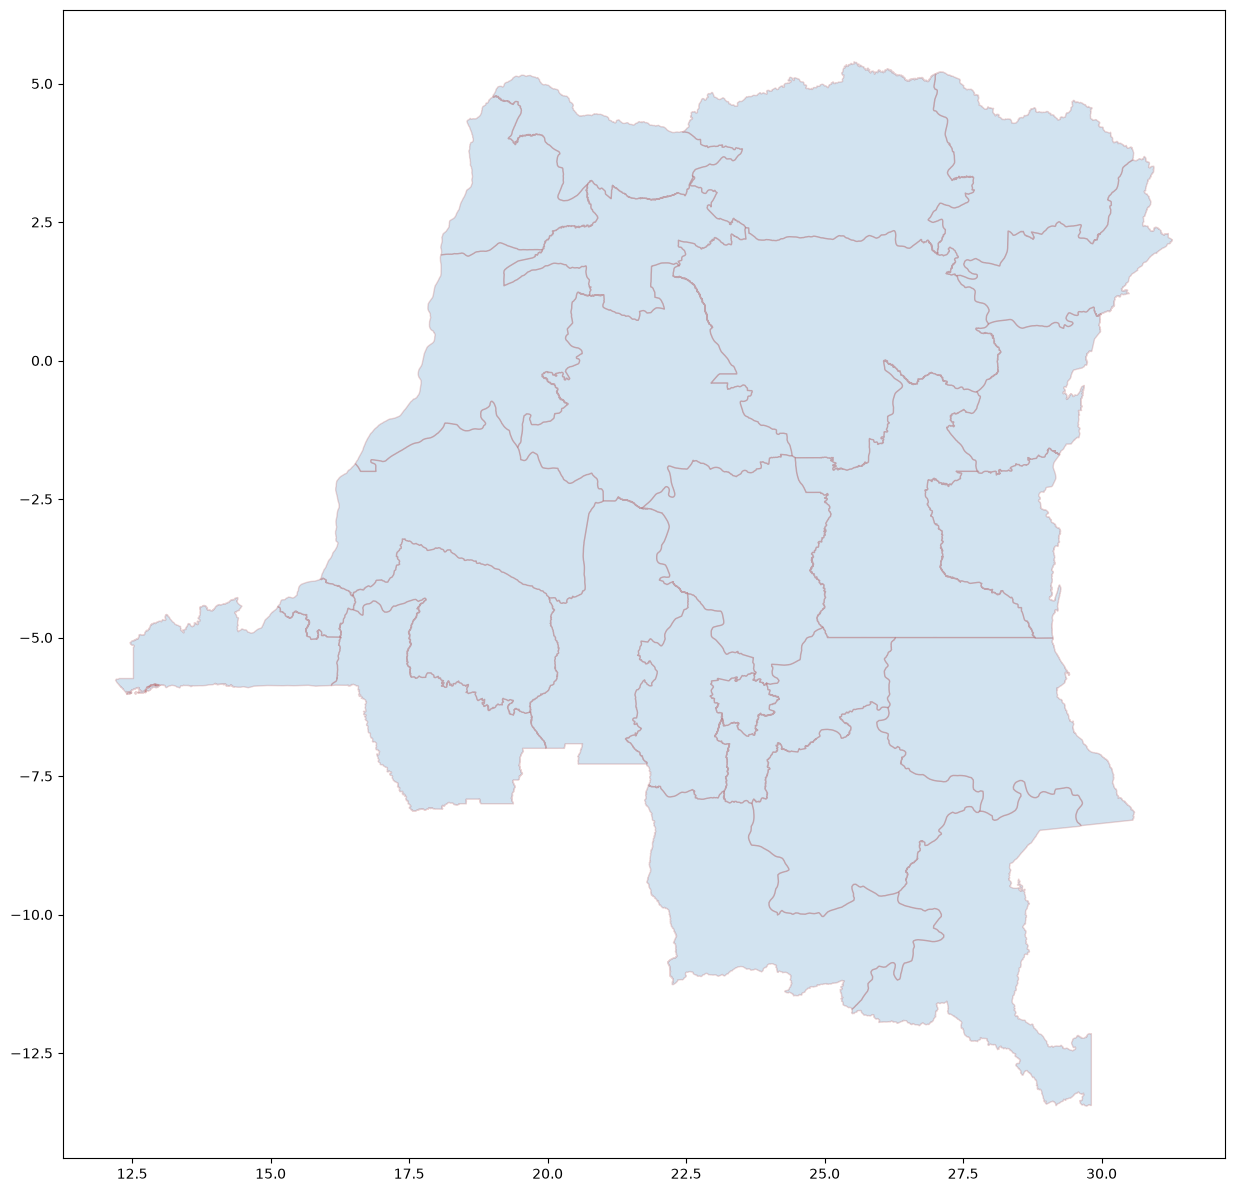

In [10]:
# Plot basemap
fig, ax = plt.subplots(figsize=(15, 15))
admin_gdf.plot(ax=ax, edgecolor='brown', alpha=0.2)
ax.set_aspect('equal', 'box')

# Save plot as figure 
#plt.savefig('admin level basemap.png', bbox_inches='tight')

**Merge tabular and admininstrative data**

In [11]:
import unicodedata

def _norm(s):
    """Normalize province name: strip accents, lowercase, collapse punctuation."""
    s = unicodedata.normalize('NFKD', str(s))
    s = ''.join(c for c in s if not unicodedata.combining(c))
    return ' '.join(s.lower().replace('-', ' ').replace('_', ' ').split())

# Normalize both join columns
admin_gdf['_key'] = admin_gdf['shapeName'].apply(_norm)
poverty_data['_key'] = poverty_data['Admin 1 Name'].apply(_norm)

# Merge on normalized name
pov_per_admin = admin_gdf.merge(poverty_data, on='_key', how='left')

# Rename poverty column and convert to percentage (OPHI reports 0-100)
pov_per_admin = pov_per_admin.rename(columns={'Headcount Ratio': 'pov_hcr'})
pov_per_admin['pov_hcr'] = pd.to_numeric(pov_per_admin['pov_hcr'], errors='coerce')

# Report unmatched provinces
unmatched = pov_per_admin[pov_per_admin['pov_hcr'].isna()]['shapeName'].tolist()
if unmatched:
    print(f"WARNING: {len(unmatched)} province(s) not matched: {unmatched}")
else:
    print(f"All {len(pov_per_admin)} provinces matched successfully.")

pov_per_admin = pov_per_admin.drop(columns=['_key'])
pov_per_admin[['shapeName', 'Admin 1 Name', 'pov_hcr']].head(5)

,shapeName,Admin 1 Name,pov_hcr
0,Upper Uele,NaN,NaN
1,Ituri,Ituri,74.3005
2,Tshopo,Tshopo,69.6289
3,Lower Uele,NaN,NaN
4,Mongala,Mongala,83.2627


In [12]:
# See the new columns in the geodataframe
pov_per_admin.columns

Index(['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType',
       'geometry', 'Country ISO3', 'Admin 1 PCode', 'Admin 1 Name', 'MPI',
       'pov_hcr', 'Intensity of Deprivation', 'Vulnerable to Poverty',
       'In Severe Poverty', 'Survey', 'Start Date', 'End Date'],
      dtype='str')

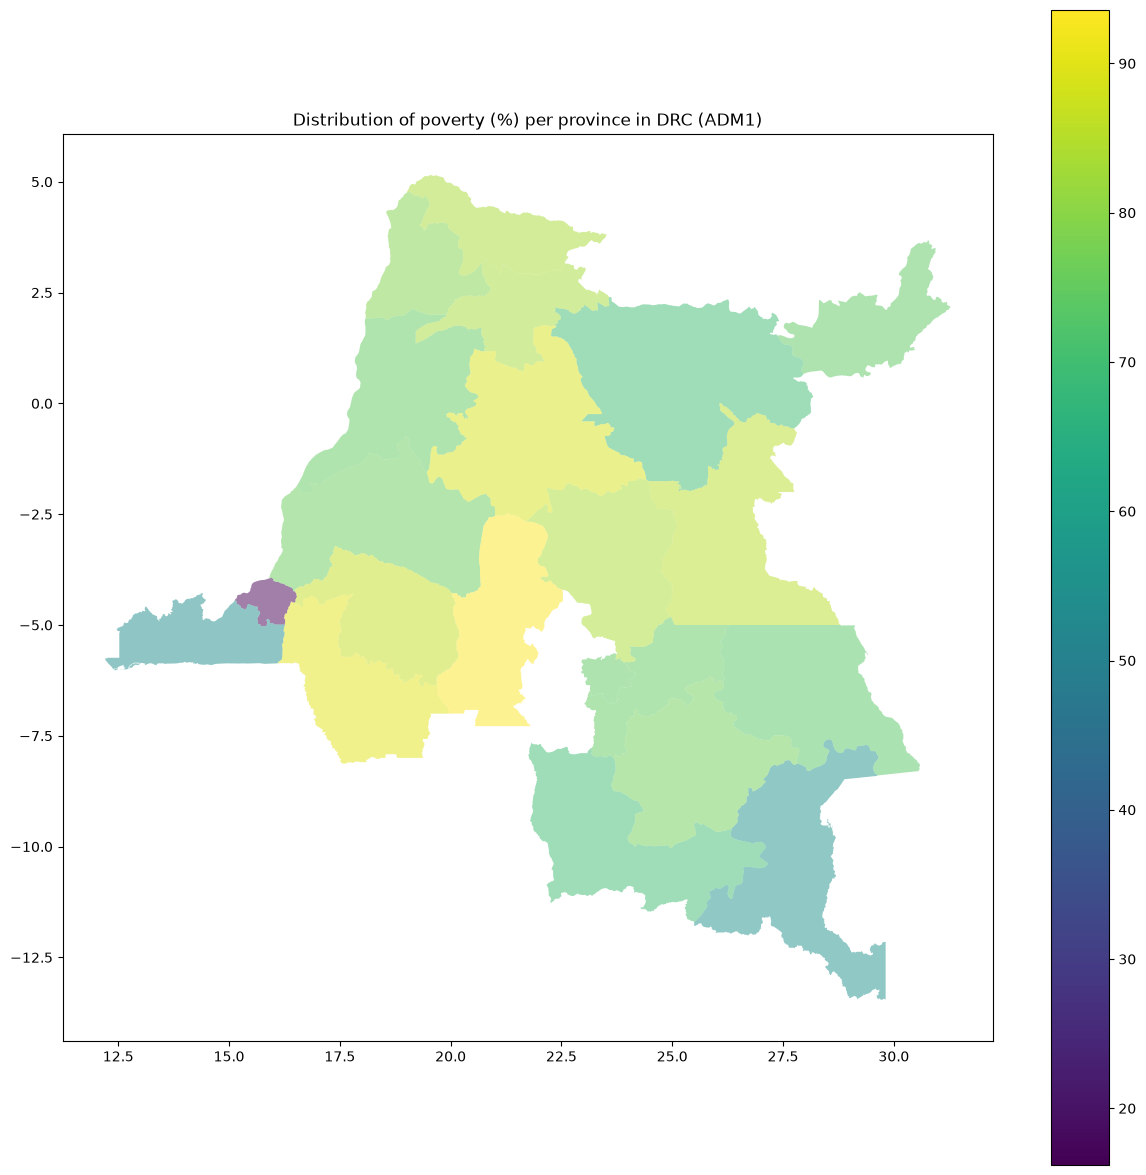

In [13]:
# Plotting for testing
fig, ax = plt.subplots(figsize=(15, 15))

pov_per_admin.sort_values('pov_hcr', ascending=True).plot(
    ax=ax, column='pov_hcr', legend=True, alpha=0.5)

ax.set_aspect('equal', 'box')
txt = ax.set_title('Distribution of {} (%) per province in DRC (ADM1)'.format("poverty"))

# Save plot as figure
#plt.savefig('sample_poverty_map.png', bbox_inches='tight')

---
**NOTE**

The dataset above is not projected. In case you want to spatially process the layer make sure you project it to the appropriate coordinate system.

---

**Export geodataframe as shapefile if needed**

In [14]:
shp_out_path = ROOT_DIR + "\\" + 'poverty_data\\shapefile'
shp_out_path

'C:\\Users\\Bachirou\\Documents\\CREDIT_Model_DRC\\Credit_DRC\\poverty_data\\shapefile'

In [15]:
shp_out_path = os.path.join(ROOT_DIR, "poverty_data", "shapefile")
os.makedirs(shp_out_path, exist_ok=True)

## Export
pov_per_admin.to_file(os.path.join(shp_out_path, "DRC_admin1.shp"))

## Project to WGS84 / UTM zone 34S (EPSG:32734) — appropriate for DRC
pov_per_admin_proj = pov_per_admin.to_crs("epsg:32734")


C:\Users\Bachirou\AppData\Local\Temp\ipykernel_12952\1407306745.py:4: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  pov_per_admin.to_file(os.path.join(shp_out_path, "{c}.shp".format(c="DRC_admin1")))
C:\Users\Bachirou\miniconda3\envs\credit_env\Lib\site-packages\pyogrio\raw.py:530: RuntimeWarning: Normalized/laundered field name: 'Country ISO3' to 'Country IS'
  ogr_write(
C:\Users\Bachirou\miniconda3\envs\credit_env\Lib\site-packages\pyogrio\raw.py:530: RuntimeWarning: Normalized/laundered field name: 'Admin 1 PCode' to 'Admin 1 PC'
  ogr_write(
C:\Users\Bachirou\miniconda3\envs\credit_env\Lib\site-packages\pyogrio\raw.py:530: RuntimeWarning: Normalized/laundered field name: 'Admin 1 Name' to 'Admin 1 Na'
  ogr_write(
C:\Users\Bachirou\miniconda3\envs\credit_env\Lib\site-packages\pyogrio\raw.py:530: RuntimeWarning: Normalized/laundered field name: 'Intensity of Deprivation' to 'Intensity'
  ogr_write(
C:\Users\Bachirou\miniconda3

---
**NOTE!!**

No matter if you create the geodataframe from the .csv data or you import it directly from a shp file, the next step requires rasterization; that is, converting the vector polygon to a raster (.tiff) output.

---

**Rasterize the poverty geo-dataframe**

In [16]:
# Define rasterizaton function
import math
def rasterize_vector(inD, outFile, field, res=0.1, dtype='float32'):
        ''' Create raster describing a field in the shapefile

        INPUT
        inD [ geopandas dataframe created from join_results ]
        outFile [ string ] - path to output raster file
        [ optional ] field [ string ] - column to rasterize from inD
        [ optional ] res [ number ] - resolution of output raster in units of inD crs
        '''

        # create metadata
        bounds = inD.total_bounds
        # calculate height and width from resolution
        width = math.ceil((bounds[2] - bounds[0]) / res)
        height = math.ceil((bounds[3] - bounds[1]) / res)

        cAffine = affine.Affine(res, 0, bounds[0], 0, res * -1, bounds[3])
        nTransform = cAffine #(res, 0, bounds[2], 0, res * -1, bounds[1])
        cMeta = {'count':1,
                 'crs': inD.crs,
                 'dtype':dtype,
                 'affine':cAffine,
                 'driver':'GTiff',
                 'transform':nTransform,
                 'height':height,
                 'width':width,
                 'nodata': 0}
        inD = inD.sort_values(by=[field], ascending=False)
        shapes = ((row.geometry, row[field]) for idx, row in inD.iterrows())
        with rasterio.open(outFile, 'w', **cMeta) as out:
            burned = features.rasterize(shapes=shapes,
                                        fill=0,
                                        all_touched=True,
                                        out_shape=(cMeta['height'], cMeta['width']),
                                        transform=out.transform,
                                        merge_alg=rasterio.enums.MergeAlg.replace)
            burned = burned.astype(cMeta['dtype'])
            out.write_band(1, burned)

In [17]:
# Rasterize & export geodataframe by calling the function

field = "pov_hcr"    # Field (column) based on which the rasterization will be based
resolution = 1000     # in meters
out_raster_name = "DRC_poverty_map.tif"
out_raster_path = os.path.join(ROOT_DIR, "poverty_data", "raster")
os.makedirs(out_raster_path, exist_ok=True)
outFile = os.path.join(out_raster_path, out_raster_name)

rasterize_vector(pov_per_admin_proj, outFile, field=field, res=resolution)

RasterioIOError: Attempt to create new tiff file 'C:/Users/Bachirou/Documents/CREDIT_Model_DRC/Credit_DRC/poverty_data/raster/DRC_poverty_map.tif' failed: No such file or directory

In [ ]:
src = rasterio.open(out_raster_path + '\\' + out_raster_name)

# getting extent from bounds fro proper vizualization
src_extent = np.asarray(src.bounds)[[0,2,1,3]]

plt.figure(figsize = (15,15))
plt.imshow(src.read(1), cmap='Reds', extent=src_extent)

plt.show()

You may want to re-project and save the raster to the original CRS for future use and/or dissemination

In [ ]:
# Define project function

def reproj(input_raster, output_raster, new_crs, factor):
    dst_crs = new_crs

    with rasterio.open(input_raster) as src:
        transform, width, height = calculate_default_transform(
            src.crs, dst_crs, src.width*factor, src.height*factor, *src.bounds)
        kwargs = src.meta.copy()
        kwargs.update({
            'crs': dst_crs,
            'transform': transform,
            'width': width,
            'height': height
        })

        with rasterio.open(output_raster, 'w', **kwargs) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, i),
                    destination=rasterio.band(dst, i),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=transform,
                    dst_crs=dst_crs,
                    resampling=Resampling.nearest)

In [ ]:
# Provide the input raster and give a name to the output (reprojected) raster
input_raster = out_raster_path + "\\" + "DRC_poverty_map.tif"
output_raster = out_raster_path + "\\" + "DRC_poverty_map_in_CRS.tif"

# Set target CRS (WGS84 geographic)
new_crs = "epsg:4326"

# Provide a factor if you want zoomed in/out results; suggest keeping it to one unless fully understanding the implications
factor = 1

In [ ]:
# Run function 
reproj(input_raster, output_raster, new_crs, factor)

### 1.2 Importing GDP data

Here we assume that GDP data is retrieved in raster format (see [source](https://gep-onsset.readthedocs.io/en/latest/GIS%20data%20collection.html#gdp-ppp)). You may clip the raster using the admin mask for the area of interest, as follows.

In [ ]:
import sys, os
sys.path.insert(0, ROOT_DIR)
from preprocess_kummu_gdp import download_file, KUMMU_V4_FILES
from extract_gdp import extract_country_gdp

gdp_path = os.path.join(ROOT_DIR, "GDP_data")
os.makedirs(gdp_path, exist_ok=True)

# Step 1 — Download Kummu v4 source raster (skips if already present)
download_file(
    url=KUMMU_V4_FILES["rast_gdpTot_1990_2024_30arcsec.tif"],
    out_dir=gdp_path,
)

# Step 2 — Extract band, clip to boundary, save
da_gdp = extract_country_gdp(
    country='COD',
    year=2024,
    gdp_path=gdp_path,
    out_path=os.path.join(gdp_path, 'GDP_2024_cod_clipped.tif'),
)
print("GDP sum (PPP):", float(da_gdp.sum()))


Plotting

In [ ]:
# Alternative way of plotting — GDP PPP 2024, DRC
gdp_file = gdp_path + '\\' + "GDP_2024_cod_clipped.tif"

with rasterio.open(gdp_file) as gdb_src:
    gdp = gdb_src.read(1)

cmap = ListedColormap(["#ffffcc", "#a1dab4", "#41b6c4", "#225ea8"])
classes = 5
breaks = (np.arange(classes) / float(classes)) * np.nanmax(gdp)
norm = colors.BoundaryNorm(list(breaks), classes)

fig, ax = plt.subplots(figsize=(15, 15))
chm_plot = ax.imshow(gdp, cmap=cmap, norm=norm)
ax.set_title("GDP PPP (2024) in DRC")

cbar = ep.colorbar(chm_plot)
boundary_means = [np.mean([norm.boundaries[ii], norm.boundaries[ii - 1]])
                  for ii in range(1, len(norm.boundaries))]

category_names = ['Low', 'Medium', 'High', 'Very High']
cbar.set_ticks(boundary_means)
cbar.set_ticklabels(category_names)
ax.set_axis_off()
plt.show()

In [ ]:
# Alternative way of plotting — GDP with poverty-based breaks, DRC
gdp_file = gdp_path + '\\' + "GDP_2024_cod_clipped.tif"

with rasterio.open(gdp_file) as gdb_src:
    gdp = gdb_src.read(1)

cmap = ListedColormap(["#ffffcc", "#a1dab4", "#41b6c4", "#225ea8"])
breaks = np.insert(poverty_bin.bins, 0, poverty_gdf.VALUE.min())

classes = len(breaks) - 1
norm = colors.BoundaryNorm(breaks, classes)

fig, ax = plt.subplots(figsize=(15, 15))
chm_plot = ax.imshow(gdp, cmap=cmap, norm=norm)
ax.set_title("GDP PPP (2024) in DRC")

cbar = ep.colorbar(chm_plot)
boundary_means = [np.mean([norm.boundaries[ii], norm.boundaries[ii - 1]])
                  for ii in range(1, len(norm.boundaries))]

category_names = ['Very Low', 'Low', 'Medium', 'High', 'Very High']
cbar.set_ticks(boundary_means)
cbar.set_ticklabels(category_names)
ax.set_axis_off()
plt.show()

## Step 2. Re-classify raster layers

The second step on the process requires that both - poverty and GDP - maps are re-classified using a 1-5 scale as shown in the table below. 

| Initial   poverty layer | Classification| Initial GDP layer | Classification |
|-------------------------|---------------|-------------------|----------------|
| 0 ≤   pov. rate < 0.2   | 5             | I1 ≤ GDP < I3     | 1              |
| 0.2 ≤   pov. rate < 0.4 | 4             | I2 ≤ GDP < I3     | 2              |
| 0.4 ≤   pov. rate < 0.6 | 3             | I3 ≤ GDP < I4     | 3              |
| 0.6 ≤   pov. rate < 0.8 | 2             | I4 ≤ GDP < I5     | 4              |
| pov. rate ≥   0.8       | 1             | GDP ≥ I5          | 5              |

The poverty map is classified using the equal interval method. The GDP map using natural breaks mentod. The classification method can have an impact on the final product layer. Please make sure you understand the differences between the methods and select the one that suits best in your case. 

You may read about this on:

- [GISing with python](https://automating-gis-processes.github.io/CSC18/lessons/L3/reclassify.html)
- [Pysal git](https://github.com/pysal/mapclassify) & [Pysal doc](https://pysal.org/scipy2019-intermediate-gds/stochastic/gds4-visualization.html)
- [GIS wiki](http://wiki.gis.com/wiki/index.php/Classification)
- [ArcGIS support](https://pro.arcgis.com/en/pro-app/help/mapping/layer-properties/data-classification-methods.htm)

---
**NOTE!!**

In the relevant [publication](https://www.mdpi.com/1996-1073/12/7/1395) GDP is reclassifed using geometric interval classification in Arcgis. You can replicate the process if you have access to ArcMap. In this notebook we will make use of the pysal library to retrieve the classification bins using different methods and then reclassify the rasters based on those bins.

---

In [ ]:
# Define working directories
temp_path = os.path.join(ROOT_DIR, "tmp")
sample_output = os.path.join(ROOT_DIR, "sample_output")
os.makedirs(temp_path, exist_ok=True)
os.makedirs(sample_output, exist_ok=True)

# Derive country boundary (ADM0) from admin layer for raster clipping
from shapely.geometry import mapping
shapes = [mapping(admin_gdf.dissolve().geometry.iloc[0])]
print(f"sample_output: {sample_output}")
print(f"Country boundary shapes ready: {len(shapes)} polygon(s)")


### Calculate classification bins

Perhaps there are faster, more sophisticated or pythonic ways to do this but here we work as follows.

- Convert raster files to geo-dataframes
- Get the bins using pysal for the selected classification method

**Convert raster files to geo-dataframes**

In [ ]:
# Define functions
from osgeo import gdal, ogr
gdal.UseExceptions()
ogr.UseExceptions()

def pixelOffset2coord(raster, xOffset,yOffset):
    geotransform = raster.GetGeoTransform()
    originX = geotransform[0]
    originY = geotransform[3]
    pixelWidth = geotransform[1]
    pixelHeight = geotransform[5]
    coordX = originX+pixelWidth*xOffset
    coordY = originY+pixelHeight*yOffset
    return coordX, coordY

def raster2array(rasterfn, band_no):
    raster = gdal.Open(rasterfn)
    band = raster.GetRasterBand(band_no)    # Be aware of the band you need here
    array = band.ReadAsArray()
    return array

def array2shp(array,outSHPfn,rasterfn):

    # max distance between points
    raster = gdal.Open(rasterfn)
    geotransform = raster.GetGeoTransform()
    pixelWidth = geotransform[1]

    srs = osr.SpatialReference()
    srs.ImportFromWkt(raster.GetProjection())
    
    # wkbPoint
    shpDriver = ogr.GetDriverByName("ESRI Shapefile")
    if os.path.exists(outSHPfn):
        shpDriver.DeleteDataSource(outSHPfn)
    outDataSource = shpDriver.CreateDataSource(outSHPfn)
    outLayer = outDataSource.CreateLayer(outSHPfn, geom_type=ogr.wkbPoint, srs=srs )
    featureDefn = outLayer.GetLayerDefn()
    outLayer.CreateField(ogr.FieldDefn("VALUE", ogr.OFTInteger))

    # array2dict
    point = ogr.Geometry(ogr.wkbPoint)
    row_count = array.shape[0]
    for ridx, row in enumerate(array):
#         print("Printing ridx..")
#         print(ridx)
        if ridx % 100 == 0:
            print ("{0} of {1} rows processed".format(ridx, row_count))
        for cidx, value in enumerate(row):
            #print("Printing cidx..")
            #print(cidx)
            #Only positive values
            if value > 0:
                Xcoord, Ycoord = pixelOffset2coord(raster,cidx,ridx)
                point.AddPoint(Xcoord, Ycoord)
                outFeature = ogr.Feature(featureDefn)
                outFeature.SetGeometry(point)
                outFeature.SetField("VALUE", float(value))
                outLayer.CreateFeature(outFeature)
                outFeature.Destroy()
                #outDS.Destroy()

def main(rasterfn,outSHPfn, band_no):
    array = raster2array(rasterfn, band_no)
    array2shp(array,outSHPfn,rasterfn)

Convert poverty map to shp to geo-dataframe & re-classify

In [ ]:
# Set input/output directories for poverty raster → shapefile conversion
inpath_pov = ROOT_DIR + "\\" + 'poverty_data\\raster'
outpath_pov = temp_path

# Provide the input raster and give a name to the output shapefile
rasterfn_pov = inpath_pov + "\\" + "DRC_poverty_map_in_CRS.tif"
outSHPfn_pov = outpath_pov + "\\" + "poverty_map_cod_in_CRS.shp"

# Run the function
main(rasterfn_pov, outSHPfn_pov, band_no=1)

In [ ]:
# Import as geodataframe
poverty_gdf = gpd.read_file(outSHPfn_pov)

In [ ]:
# Get bins based on the poverty geodataframe created above
import mapclassify as mc
poverty_bin = mc.UserDefined(poverty_gdf.VALUE, bins=[20, 40, 60, 80, 100])
poverty_bin

In [ ]:
# Re-classify -- code retrieved from https://gis.stackexchange.com/questions/163007/raster-reclassify-using-python-gdal-and-numpy

with rasterio.open(rasterfn_pov) as pov_src:
    # Read the raster into a (rows, cols, depth) array,
    # dstack this into a (depth, rows, cols) array,
    # the sum along the last axis (~= grayscale)
    pov_grey = np.mean(np.dstack(pov_src.read()), axis=2)

    # Read the file profile
    srcprof = pov_src.profile.copy()

#breaks = (np.arange(classes) / float(classes)) * pov_grey.max()
breaks = poverty_bin.bins

# classify the raster
classified = np.sum(np.dstack([(pov_grey < b) for b in breaks]), axis=2).reshape(1, pov_grey.shape[0], pov_grey.shape[1]).astype(np.int32)

#lookup = [(0, 3),(1, 5),(2, 4),(3, 3),(4, 2), (5, 1)]
lookup = [(0, 3)]
lookup = np.asarray(lookup)
replacer = np.arange(classified.max() + 1)
replacer[lookup[:, 0]] = lookup[:, 1]
classified = replacer[classified]

# Update the file opts to one band
srcprof.update(count=1, nodata=None, dtype=classified.dtype)

with rasterio.open(outpath_pov + '\\' + 'poverty_map_in_CRS_classified.tif', 'w', **srcprof) as dst:
    # Write the output
    dst.write(classified)

Convert gdp map to shp to geo-dataframe & re-classify

In [ ]:
# Set input/output directories for GDP raster → shapefile conversion
inpath_gdp = ROOT_DIR + "\\" + 'GDP_data'
outpath_gdp = temp_path

# Provide the input raster and give a name to the output shapefile
rasterfn_gdp = inpath_gdp + "\\" + "GDP_2024_cod_clipped.tif"
outSHPfn_gdp = outpath_gdp + "\\" + "GDP_2024_cod_clipped.shp"

# Run the function
main(rasterfn_gdp, outSHPfn_gdp, band_no=1)

In [ ]:
# Import as geodataframe
gdp_gdf = gpd.read_file(outSHPfn_gdp)

In [ ]:
# Get bins based on the poverty geodataframe created above
gdp_bin = mc.NaturalBreaks(gdp_gdf.VALUE, k=5)
gdp_bin

In [ ]:
with rasterio.open(rasterfn_gdp) as gdp_src:
    gdp_grey = np.mean(np.dstack(gdp_src.read()), axis=2)
    srcprof = gdp_src.profile.copy()

valid_mask = ~np.isnan(gdp_grey)

breaks = gdp_bin.bins
classified = np.sum(np.dstack([(gdp_grey < b) for b in breaks]), axis=2)

lookup = [(0, 5), (1, 5), (2, 4), (3, 3), (4, 2), (5, 1)]
lookup = np.asarray(lookup)
replacer = np.arange(classified.max() + 1)
replacer[lookup[:, 0]] = lookup[:, 1]
classified = replacer[classified]

classified = np.where(valid_mask, classified, 0).reshape(1, gdp_grey.shape[0], gdp_grey.shape[1]).astype(np.int32)

srcprof.update(count=1, nodata=0, dtype=classified.dtype)
with rasterio.open(outpath_gdp + '\\' + 'GDP_2024_cod_clipped_classified.tif', 'w', **srcprof) as dst:
    dst.write(classified)

## Step 3. Sum the re-classified layers 

Here we sum the (weighted) re-classified layers to create a combined index ranging from 1-5. The operation is relatively simple and can be represented as follows:

<center>(poverty_reclas X weight_1) + (gdp_reclas X weight_2)   |   where weight_1 + weight_2 = 1</center>

---
**Note!**

- One easy way of doing this is by using raster calculator tools in a GIS environment ([Qgis](https://docs.qgis.org/2.8/en/docs/user_manual/working_with_raster/raster_calculator.html) or [ArcMap](https://desktop.arcgis.com/en/arcmap/10.3/tools/spatial-analyst-toolbox/raster-calculator.htm)).


- In case one wants to work in python only, alternative options include the [gdal_calc](https://gdal.org/programs/gdal_calc.html) code or even [rio calc](https://rasterio.readthedocs.io/en/latest/topics/calc.html). However, this requires that the raster layers are entirely alligned, as the operation is taking place on their respective arrays (see **Option 1** below)


- Alternatively, one might follow a less efficient approach that involves several transformations. Nevertheless, the approach works and yields the desired result regardless of the size of input rasters (see **Option 2** below).

Feel free to use use as per your understanding and convenience!

---

### Option 1 -- Re-sizing raster arrays based on shape

In [ ]:
from shapely.geometry import box
from rasterio.warp import reproject, Resampling
from affine import Affine

with rasterio.open(outpath_pov + '\\' + 'poverty_map_in_CRS_classified.tif') as raster1, \
     rasterio.open(outpath_gdp + '\\' + 'GDP_2024_cod_clipped_classified.tif') as raster2:

    bb1 = box(*raster1.bounds)
    bb2 = box(*raster2.bounds)
    intersection = bb1.intersection(bb2)
    minx, miny, maxx, maxy = intersection.bounds

    # Build output grid at raster1's resolution, covering only the overlap
    res = raster1.res[0]
    width = int((maxx - minx) / res)
    height = int((maxy - miny) / res)
    out_transform = Affine(res, 0.0, minx, 0.0, -res, maxy)

    # Read raster1's data directly via windowed read (same grid, no resampling needed)
    window1 = rasterio.windows.from_bounds(minx, miny, maxx, maxy, transform=raster1.transform)
    arr1 = raster1.read(1, window=window1, out_shape=(height, width), resampling=Resampling.nearest)

    # Resample raster2 onto the exact same output grid
    arr2 = np.zeros((height, width), dtype=raster2.dtypes[0])
    reproject(
        source=rasterio.band(raster2, 1),
        destination=arr2,
        src_transform=raster2.transform,
        src_crs=raster2.crs,
        dst_transform=out_transform,
        dst_crs=raster1.crs,
        resampling=Resampling.nearest  # nearest — these are discrete classes, not continuous
    )

    valid_mask = (arr1 != 0) & (arr2 != 0)
    weight_pov, weight_gdp = 0.5, 0.5  # confirm against your methodology

    arr_sum = (arr1 * weight_pov) + (arr2 * weight_gdp)
    arr_sum = np.where(valid_mask, arr_sum, 0).astype('float32')

    out_profile = raster1.profile.copy()
    out_profile.update(height=height, width=width, transform=out_transform, count=1, nodata=0, dtype='float32')

    with rasterio.open(sample_output + "\\" + "AHP_option_1.tif", 'w', **out_profile) as dst:
        dst.write(arr_sum, 1)

---

**Note!**
In case the process reports arraey out of bounds simply re-assign raster1 and raster 2.


---

In [ ]:
# Clip raster file to admin level
# Import raster, clip and export
clip_path = sample_output
clip_name = 'AHP_option_1.tif'
with rasterio.open(clip_path + '\\' + clip_name) as src:
    out_image, out_transform = rasterio.mask.mask(src, shapes, crop=True)
    out_meta = src.meta
    
out_meta.update({"driver": "GTiff",
                 "height": out_image.shape[1],
                 "width": out_image.shape[2],
                 "transform": out_transform})

with rasterio.open(sample_output + '\\'+"clipped_sum_.tif", "w", **out_meta) as dest:
    dest.write(out_image)

In [ ]:
# Alternative way of plotting
sample_file = sample_output + '\\'+"clipped_sum_.tif"

with rasterio.open(sample_file) as src:
    sample_out = src.read(1)       # pay attention to the band here, in this case band 3 gives values of 2015

# Define the colors you want
cmap = ListedColormap(["white", "tan", "springgreen", "darkgreen"])

# Define a normalization from values -> colors
classes = 5
breaks = (np.arange(classes) / float(classes)) * sample_out.max()    # This is an example that serves only visualization purposes at this point; see classification below for more info on dirrerent was to retrieve bins

norm = colors.BoundaryNorm(list(breaks),classes)

fig, ax = plt.subplots(figsize=(15, 15))

chm_plot = ax.imshow(sample_out,
                     cmap=cmap,
                     norm=norm)

ax.set_title("AHP layer")

# Scale color bar to the height of the plot
cbar = ep.colorbar(chm_plot)

boundary_means = [np.mean([norm.boundaries[ii], norm.boundaries[ii - 1]])
                  for ii in range(1, len(norm.boundaries))]

category_names = [ 'Low', 'Medium', 'High', 'Very High']
cbar.set_ticks(boundary_means)
cbar.set_ticklabels(category_names)

ax.set_axis_off()
plt.show()

### Option 2 -- Converting raster to geodataframe and work accordingly

### 3.1 Create a "base" point layer as a csv file

Here we use one of the geo-dataframes (either poverty or gdp) to create a vector point layer that we will use as base. It is suggested to use the one that yield the resolution that best suits each case. Here we proceed with the GDP geo-dataframe.

In [ ]:
# Stored in memory from previous steps
gdp_gdf.head(3)

In [ ]:
# Creating an index ("idx") column to be used for merging dataframes later on
gdp_gdf['idx'] = range(1, len(gdp_gdf) + 1)

In [ ]:
# Extract geometry as X,Y coordinates
gdp_gdf['lon'] = gdp_gdf['geometry'].x
gdp_gdf['lat'] = gdp_gdf['geometry'].y

In [ ]:
# Export the dataframe as csv file 
gdp_gdf.to_csv(os.path.join(temp_path,"{c}.csv".format(c='base')), index=False)

### 3.2 Extract raster values to points defined by the "base" csv file

---

**Note!** In case this takes time, you may want to clip the rasters using the region's admin layer as mask (see code below). In the sample case the difference in time gained is small and we use directly the rasters files from the previous step.

---


In [ ]:
raster_path = temp_path
raster_files =[]
csvoutpath = temp_path

print ("Reading independent variables...")

for i in os.listdir(raster_path):
    if i.endswith('.tif'):
        raster_files.append(i)  

print ("Extracting raster values to points...")

for i in raster_files:
    print("Extracting " + i + " values...")
    src_filename = raster_path + "\\" + i 
    li_values = list()

    src_ds=gdal.Open(src_filename) 
    gt=src_ds.GetGeoTransform()
    rb=src_ds.GetRasterBand(1)
    #ds=ogr.Open(shp_filename)
    ds = ogr.Open(gdp_gdf.to_json())
    lyr=ds.GetLayer()
    
    for feat in lyr:
        geom = feat.GetGeometryRef()
        feat_id = feat.GetField('idx')
        mx,my=geom.GetX(), geom.GetY()  #coord in map units

        #Convert from map to pixel coordinates.
        #Only works for geotransforms with no rotation.
        px = int((mx - gt[0]) / gt[1]) #x pixel
        py = int((my - gt[3]) / gt[5]) #y pixel

        intval=rb.ReadAsArray(px,py,1,1)
        li_values.append([feat_id, intval[0]])
        
    print ("Writing " + i + " values to csv...")
    
    with open(csvoutpath + "\\" + i.split('.')[0] + '.csv', 'w') as csvfile:
        wr = csv.writer(csvfile)
        wr.writerows(li_values) 

### 3.3 Merge all csv files & create a dataframe from them

In [ ]:
pov_gdp = pd.read_csv(temp_path + "\\" + "base.csv")

csv_files = []

print ("Reading csv files...")

for i in os.listdir(csvoutpath):
    if i.endswith('.csv'):
        csv_files.append(i)  

for i in csv_files:
    print('Reading...'+ i)    
    df_csv = pd.read_csv(csvoutpath + "//" + i, index_col=None, header=None)
    df_csv.iloc[:,1] = df_csv.iloc[:,1].astype(str)
    df_csv.iloc[:,1] = df_csv.iloc[:,1].str.replace('[','')
    df_csv.iloc[:,1] = df_csv.iloc[:,1].str.replace(']','')
    columnName = i.split('.')[0]
    print("Merging..." + columnName)
    pov_gdp[columnName] = df_csv.iloc[:,1]

In [ ]:
pov_gdp.head(2)

**Cleaning and prepping**

In [ ]:
#Delete geometry column
pov_gdp = pov_gdp.drop(["base", "VALUE", "geometry"], axis=1)

In [ ]:
pov_gdp.GDP_2024_cod_clipped_classified.unique()

In [ ]:
# Convert nan to 0
pov_gdp["GDP_2024_cod_clipped_classified"] = pov_gdp["GDP_2024_cod_clipped_classified"].fillna(3)
pov_gdp["poverty_map_in_CRS_classified"] = pov_gdp["poverty_map_in_CRS_classified"].fillna(3)

# Changing dtype of classified columns
pov_gdp["GDP_2024_cod_clipped_classified"] = pov_gdp["GDP_2024_cod_clipped_classified"].astype(int)
pov_gdp["poverty_map_in_CRS_classified"] = pov_gdp["poverty_map_in_CRS_classified"].astype(int)

In [ ]:
pov_gdp.head(2)

### 3.4 Adding the two classified columns using weighting factors

In [ ]:
# Selecting weights — note that the sum must equal 1
weight_pov = 0.5
weight_gdp = 0.5

pov_gdp['AHP_index'] = (pov_gdp['GDP_2024_cod_clipped_classified'] * weight_gdp) + (pov_gdp['poverty_map_in_CRS_classified'] * weight_pov)

In [ ]:
pov_gdp.head(2)

In [ ]:
# Creating a geo-dataframe - appointing geometry attribute
pov_gdp['geometry'] = list(zip(pov_gdp['lon'], pov_gdp['lat']))
pov_gdp['geometry'] = pov_gdp['geometry'].apply(Point)
pov_gdp_gdf = gpd.GeoDataFrame(pov_gdp, geometry='geometry', crs='epsg:4326')

In [ ]:
# Create the axis first
fig, ax = plt.subplots(figsize=(25, 25))
#admin_gdf.plot(ax=ax, edgecolor='brown', alpha=0.2)
pov_gdp_gdf.sort_values('AHP_index', ascending=True).plot(ax=ax, column='AHP_index',
                           legend=True, markersize=3, cmap="viridis",
                           figsize=(20, 20), alpha=0.5)
# Make figure aspect ratio ensure that 10x10 km square appears square
ax.set_aspect('equal', 'box')
txt = ax.set_title('Result of the AHP process'.format(""))

# Save plot as figure 
plt.savefig(os.path.join(sample_output, 'AHP_result_option2.png'), bbox_inches='tight')
#logging.getLogger('matplotlib.font_manager').disabled = True



## Step 4. Interpolate and create the CRETID layer


In [ ]:
# MTF-based demand interpolation for DRC
# DRC average household size: ~5.3 people (vs Malawi ~4.6)
# Values are kWh/capita/year, scaled from Malawi MTF targets using HH size ratio (4.6/5.3 ≈ 0.868)
# Min (Tier 1): ~7.6 kWh/capita/year | Max (Tier 5): ~590 kWh/capita/year
# NOTE: verify these values against official DRC MTF calibration data before use in production.
x = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
y = [1, 7.6, 153.3, 299.0, 444.7, 590.4]
y_interp = scipy.interpolate.interp1d(x, y)

pov_gdp_gdf["CREDIT"] = y_interp(pov_gdp_gdf["AHP_index"])

In [ ]:
# Create the axis first
fig, ax = plt.subplots(figsize=(25, 25))
#admin_gdf.plot(ax=ax, edgecolor='brown', alpha=0.2)
pov_gdp_gdf.sort_values('CREDIT', ascending=True).plot(ax=ax, column='CREDIT',
                           legend=True, markersize=3, cmap="viridis",
                           figsize=(20, 20), alpha=0.5)
# Make figure aspect ratio ensure that 10x10 km square appears square
ax.set_aspect('equal', 'box')
txt = ax.set_title('Sample CREDIT layer'.format(""))

# Save plot as figure 
plt.savefig(os.path.join(sample_output, 'Sample_result.png'), bbox_inches='tight')
logging.getLogger('matplotlib.font_manager').disabled = True

In [ ]:
# Reproject to WGS84 / UTM zone 34S (EPSG:32734) — appropriate for DRC
pov_gdp_gdf_proj = pov_gdp_gdf.to_crs('epsg:32734')

In [ ]:
# Rasterize & export geodataframe by calling the function

field = "CREDIT"    # Field (column) based on which the rasterization will be based
resolution = 1000     # in metersg
out_raster_name = 'CREDIT.tif'

out_raster_path = ROOT_DIR + "\\" + 'sample_output'
outFile = os.path.join(out_raster_path, out_raster_name)

rasterize_vector(pov_gdp_gdf_proj, outFile, field=field, res=resolution)